# NIFTY 50 Stock Price Prediction
## Hybrid ARIMA + Deep Learning Time Series Forecasting Framework

This notebook implements a state-of-the-art predictive pipeline for the **NIFTY 50 Index (`^NSEI`)** combining classical statistical time series modeling (**ARIMA**) with advanced Deep Learning architectures (**LSTM**, **Bidirectional LSTM**, **GRU**, and **Deep Multi-Layer GRU**).

### Key Methodological Highlights:
1. **Data Ingestion**: Historical daily stock prices fetched via Yahoo Finance (2015 to 2025) with offline caching.
2. **Stationarity Analysis**: Augmented Dickey-Fuller (ADF) and KPSS statistical tests on log-prices and first differences.
3. **ARIMA Residual Extraction**: ARIMA(1,1,0) modeling on differenced series to capture linear structure and reconstruct cumulative hybrid target series.
4. **Leakage-Free Preprocessing**: Scaling with `MinMaxScaler` fitted strictly on training data (70/30 split) with 60-day sliding lookback windows.
5. **Multi-Model Benchmark**: Comprehensive evaluation using RMSE, MAE, MAPE (%), MASE, and R² score across all 4 deep learning models.


In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import requests

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout, LSTM, Bidirectional, GRU
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Libraries imported successfully!')
print(f'TensorFlow Version: {tf.__version__} | yfinance Version: {yf.__version__}')


Libraries imported successfully!
TensorFlow Version: 2.21.0 | yfinance Version: 1.7.0


### 1. Data Ingestion & Preprocessing
We download historical daily data for the NIFTY 50 index (`^NSEI`) from Yahoo Finance (from January 2015 to July 2025).

In [2]:
stock_ticker = '^NSEI'
cache_file = os.path.join('data', 'nifty50_data.csv')
os.makedirs('data', exist_ok=True)

try:
    session = requests.Session()
    session.headers['User-Agent'] = 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'
    raw_df = yf.download(stock_ticker, start='2015-01-01', end='2025-07-31', session=session, timeout=15)
    if isinstance(raw_df.columns, pd.MultiIndex):
        raw_df.columns = raw_df.columns.get_level_values(0)
    raw_df.reset_index(inplace=True)
    df = raw_df[['Date', 'Close']].copy()
    df.rename(columns={'Date': 'date', 'Close': 'close'}, inplace=True)
    df['close'] = df['close'].astype(float)
    df['date'] = pd.to_datetime(df['date']).dt.date
    df.dropna(inplace=True)
    df.to_csv(cache_file, index=False)
except Exception as e:
    print(f'Fetching from cache due to: {e}')
    df = pd.read_csv(cache_file)
    df['date'] = pd.to_datetime(df['date']).dt.date
    df['close'] = df['close'].astype(float)

print(f'Total trading days loaded: {len(df)}')
df.head()


[*********************100%***********************]  1 of 1 completed

Total trading days loaded: 2604


Price,date,close
0,2015-01-02,8395.450195
1,2015-01-05,8378.400391
2,2015-01-06,8127.350098
3,2015-01-07,8102.100098
4,2015-01-08,8234.599609


In [3]:
df2 = pd.DataFrame(index=df['date'])
df2['close'] = np.log(df['close'].values)
df2.head()


,close
date,
2015-01-02,9.035445
2015-01-05,9.033412
2015-01-06,9.002990
2015-01-07,8.999879
2015-01-08,9.016100


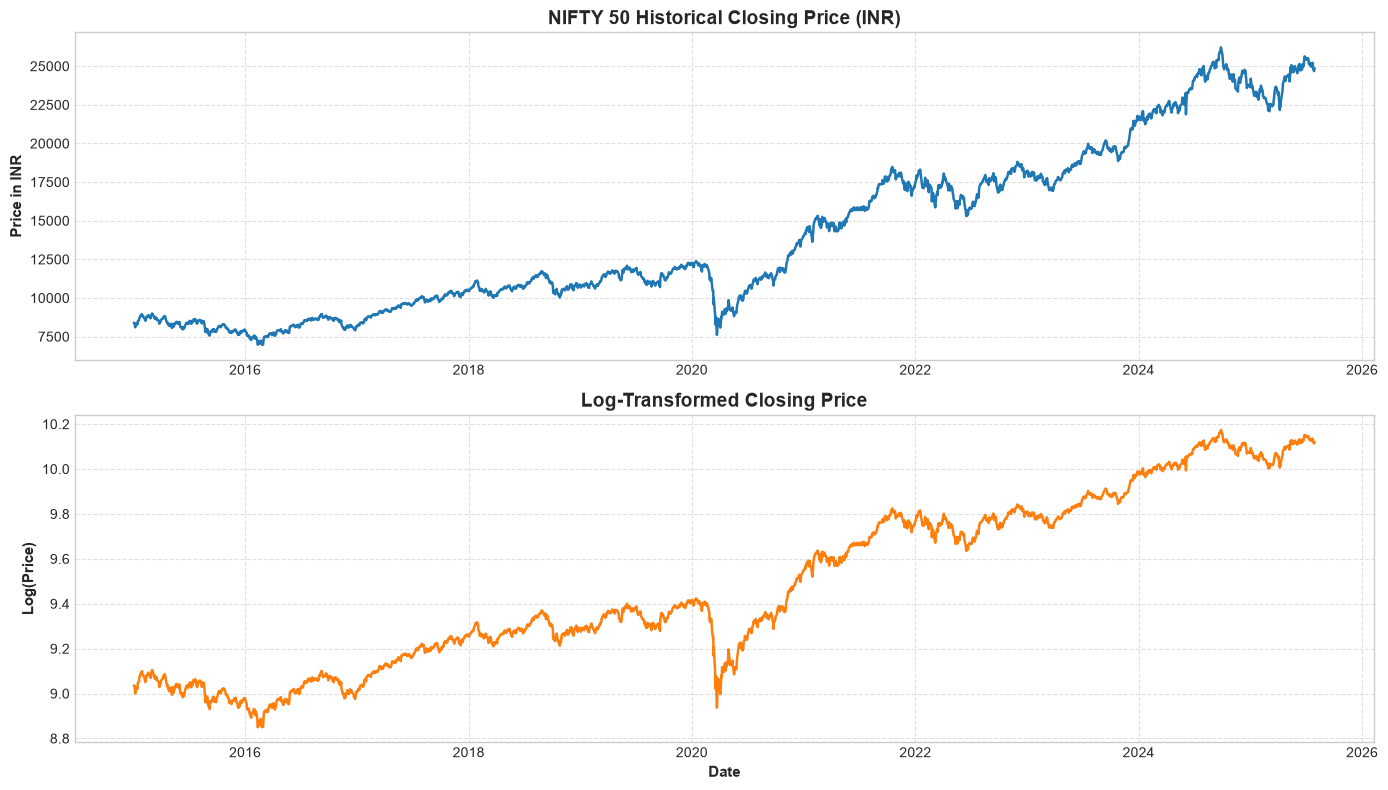

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))
ax1.plot(pd.to_datetime(df['date']), df['close'], color='#1f77b4', linewidth=1.8)
ax1.set_title('NIFTY 50 Historical Closing Price (INR)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Price in INR', fontsize=11, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(pd.to_datetime(df['date']), df2['close'], color='#ff7f0e', linewidth=1.8)
ax2.set_title('Log-Transformed Closing Price', fontsize=14, fontweight='bold')
ax2.set_ylabel('Log(Price)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Date', fontsize=11, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


### 2. Stationarity Analysis (ADF & KPSS Tests)
We perform the **Augmented Dickey-Fuller (ADF)** and **Kwiatkowski-Phillips-Schmidt-Shin (KPSS)** tests to evaluate stationarity before and after differencing.

In [5]:
def check_adf(series, name='Series'):
    result = adfuller(series.dropna())
    print(f'ADF Test [{name}]:')
    print(f'  ADF Statistic: {result[0]:.6f}')
    print(f'  p-value: {result[1]:.6e}')
    if result[1] <= 0.05:
        print('  => Series IS stationary (Reject H0).')
    else:
        print('  => Series is NOT stationary (Fail to reject H0).')

def check_kpss(series, name='Series'):
    stat, p_val, lags, crit_vals = kpss(series.dropna(), regression='c', nlags='auto')
    print(f'KPSS Test [{name}]:')
    print(f'  KPSS Statistic: {stat:.6f}')
    print(f'  p-value: {p_val:.6f}')
    if p_val >= 0.05:
        print('  => Series IS stationary (Fail to reject H0).')
    else:
        print('  => Series is NOT stationary (Reject H0).')

print('--- Tests on Log Price ---')
check_adf(df2['close'], 'Log Close')
print()
check_kpss(df2['close'], 'Log Close')

# First Differencing
df2['FirstDifference'] = df2['close'] - df2['close'].shift(1)
df2.dropna(inplace=True)

print('\n--- Tests on First Differenced Series ---')
check_adf(df2['FirstDifference'], 'First Difference')
print()
check_kpss(df2['FirstDifference'], 'First Difference')


--- Tests on Log Price ---
ADF Test [Log Close]:
  ADF Statistic: -0.190445
  p-value: 9.396510e-01
  => Series is NOT stationary (Fail to reject H0).

KPSS Test [Log Close]:
  KPSS Statistic: 8.073869
  p-value: 0.010000
  => Series is NOT stationary (Reject H0).

--- Tests on First Differenced Series ---
ADF Test [First Difference]:
  ADF Statistic: -14.130429
  p-value: 2.338931e-26
  => Series IS stationary (Reject H0).

KPSS Test [First Difference]:
  KPSS Statistic: 0.069206
  p-value: 0.100000
  => Series IS stationary (Fail to reject H0).


C:\Users\user22\AppData\Local\Temp\18\ipykernel_34704\3317163392.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  stat, p_val, lags, crit_vals = kpss(series.dropna(), regression='c', nlags='auto')
C:\Users\user22\AppData\Local\Temp\18\ipykernel_34704\3317163392.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_val, lags, crit_vals = kpss(series.dropna(), regression='c', nlags='auto')


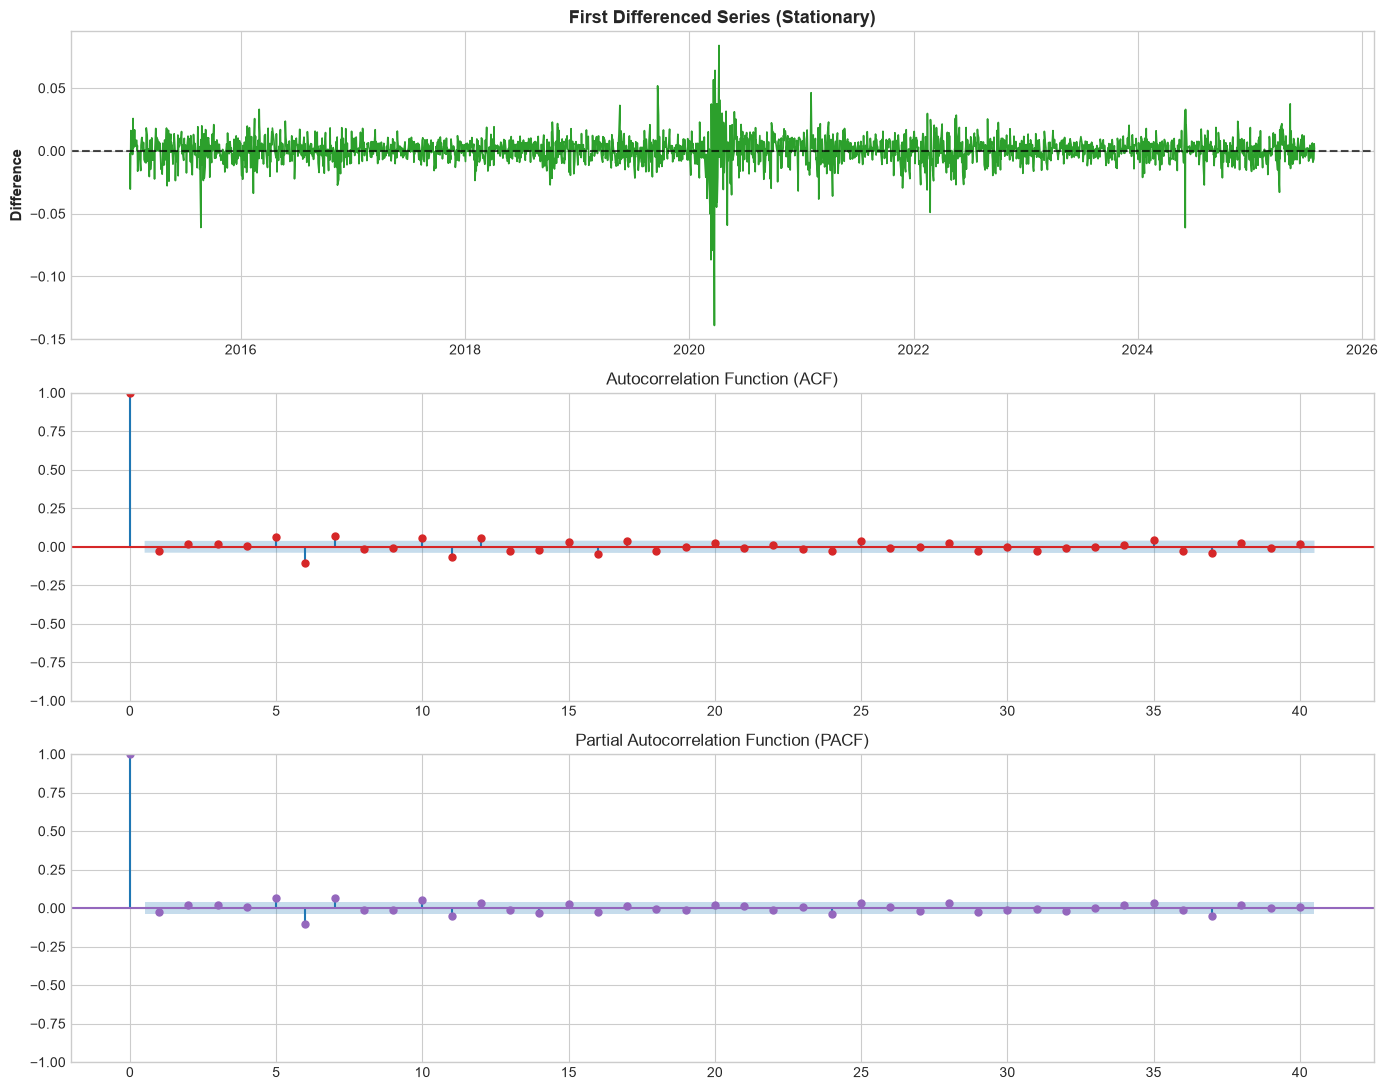

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))

axes[0].plot(df2.index, df2['FirstDifference'], color='#2ca02c', linewidth=1.2)
axes[0].axhline(0, color='black', linestyle='--', alpha=0.7)
axes[0].set_title('First Differenced Series (Stationary)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Difference', fontsize=11, fontweight='bold')

plot_acf(df2['FirstDifference'], ax=axes[1], lags=40, color='#d62728', title='Autocorrelation Function (ACF)')
plot_pacf(df2['FirstDifference'], ax=axes[2], lags=40, color='#9467bd', title='Partial Autocorrelation Function (PACF)')

plt.tight_layout()
plt.show()


### 3. ARIMA Model Fitting & Hybrid Feature Extraction (Contamination-Free)
We fit an **ARIMA(1, 0, 0)** model directly on the already-stationary `FirstDifference` series.

> **Why `d=0`?** The ADF test (p < 1e-25) and KPSS test both confirm `FirstDifference` is already stationary.
> Passing `d=1` on a stationary series causes **over-differencing** — equivalent to `d=2` on raw log prices —
> which introduces artificial MA roots and worsens AIC by ~1,051 points (AIC: −15,303 vs −16,354).

**Fix 3 — Train/Test Contamination removed:**
- Previously, ARIMA was fit on the **entire 2015–2025 dataset** before splitting, contaminating test residuals with future data.
- Now, ARIMA is fit **strictly on the training partition (70%)** and applied to the test partition using **`model.apply(refit=False)`** — frozen coefficients, no re-estimation on test data.

The cumulative residuals are combined with lagged log prices to form the **causal hybrid target series**.

In [7]:
# ── Fix 3: Split FIRST, then fit ARIMA on train only ────────────────────────
TRAIN_RATIO = 0.70
full_series  = df2['FirstDifference'].dropna()
split_idx    = int(len(full_series) * TRAIN_RATIO)
train_diff   = full_series.iloc[:split_idx]
test_diff    = full_series.iloc[split_idx:]

# Fit ARIMA(1,0,0) STRICTLY on training partition (no future data)
arima_model  = ARIMA(train_diff, order=(1, 0, 0))
arima_result = arima_model.fit()
print(arima_result.summary())
print(f'ARIMA AIC: {arima_result.aic:.4f} | BIC: {arima_result.bic:.4f}')

# Out-of-sample residuals on test — frozen coefficients, no re-fitting
test_applied = arima_result.apply(test_diff, refit=False)

# Concatenate in-sample (train) + out-of-sample (test) residuals
all_resid = pd.concat([arima_result.resid, test_applied.resid]).sort_index()

# Causal cumulative residuals + lagged log price reconstruction
cumulative_resid = all_resid.cumsum()
a = df2['close'] - df2['FirstDifference']   # = ln(P_{t-1})
diff_results = cumulative_resid + a

df1 = diff_results.dropna()
print(f'Train residuals: {len(arima_result.resid)} | Test residuals: {len(test_applied.resid)}')
print(f'Hybrid series size: {len(df1)}')


                               SARIMAX Results                                
Dep. Variable:        FirstDifference   No. Observations:                 1822
Model:                 ARIMA(1, 0, 0)   Log Likelihood                5580.549
Date:                Fri, 28 Aug 2026   AIC                         -11155.099
Time:                        21:28:36   BIC                         -11138.576
Sample:                             0   HQIC                        -11149.003
                               - 1822                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      1.378      0.168      -0.000       0.001
ar.L1         -0.0280      0.013     -2.160      0.031      -0.053      -0.003
sigma2         0.0001   1.65e-06     77.704      0.0

C:\Users\user22\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\user22\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\user22\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\user22\AppData\Roaming\Python\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequ

### 4. Leakage-Free Train/Test Split & Lookback Window Generation
To prevent lookahead bias and data leakage, the `MinMaxScaler` is strictly fitted **only on the training partition (70%)** and then applied to transform the test partition (30%).

In [8]:
df1_raw = np.array(df1).reshape(-1, 1)

training_size = int(len(df1_raw) * 0.70)
test_size = len(df1_raw) - training_size

train_raw = df1_raw[:training_size]
test_raw  = df1_raw[training_size:]

scaler = MinMaxScaler(feature_range=(0, 1))
train_data = scaler.fit_transform(train_raw)   # Fit ONLY on train
test_data  = scaler.transform(test_raw)        # Transform-only on test

def create_dataset(dataset, time_step=60):
    dataX, dataY = [], []
    # Correct boundary: range(len - time_step) ensures the latest trading day is included
    for i in range(len(dataset) - time_step):
        a = dataset[i:(i + time_step)]
        dataX.append(a)
        dataY.append(dataset[i + time_step])
    return np.array(dataX), np.array(dataY)

time_step = 60
X_train, y_train = create_dataset(train_data, time_step)
X_test, y_test = create_dataset(test_data, time_step)

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

test_dates = df1.index[training_size + time_step : training_size + time_step + len(y_test)]

print(f'X_train shape: {X_train.shape} | y_train shape: {y_train.shape}')
print(f'X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}')
print(f'Test Dates:    {test_dates[0]} to {test_dates[-1]} ({len(test_dates)} trading days)')


X_train shape: (1762, 60, 1) | y_train shape: (1762, 1)
X_test shape:  (721, 60, 1)  | y_test shape:  (721, 1)
Test Dates:    2022-08-30 to 2025-07-30 (721 trading days)


In [9]:
def calculate_metrics(y_true_s, y_pred_s, y_train_s, model_name):
    yt = y_true_s.reshape(-1)
    yp = y_pred_s.reshape(-1)
    mse = mean_squared_error(yt, yp)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(yt, yp)
    mape = mean_absolute_percentage_error(yt, yp)
    r2 = r2_score(yt, yp)
    naive_diff = np.mean(np.abs(np.diff(y_train_s.reshape(-1))))
    mase = mae / (naive_diff if naive_diff != 0 else 1e-8)
    return {
        'Model': model_name,
        'RMSE': rmse,
        'MSE': mse,
        'MAE': mae,
        'MAPE (%)': mape * 100,
        'MASE': mase,
        'R2': r2
    }

def plot_forecast(test_dates, df_log_close, test_predict_s, scaler, model_name, metrics):
    actual = np.exp(df_log_close.loc[test_dates, 'close'].values)
    pred = np.exp(scaler.inverse_transform(test_predict_s).reshape(-1))
    
    plt.figure(figsize=(14, 6))
    plt.plot(test_dates, actual, label='Actual NIFTY 50 Price', color='#d62728', linewidth=2.0)
    plt.plot(test_dates, pred, label=f'{model_name} Prediction', color='#2ca02c', linewidth=2.0, linestyle='--')
    plt.title(f'{model_name} Forecast vs Actual Price | RMSE: {metrics["RMSE"]:.4f}, MAPE: {metrics["MAPE (%)"]:.2f}%, MASE: {metrics["MASE"]:.4f}', fontsize=13, fontweight='bold')
    plt.ylabel('Price in INR', fontsize=11, fontweight='bold')
    plt.xlabel('Date', fontsize=11, fontweight='bold')
    plt.legend(frameon=True)
    plt.show()
    return pd.DataFrame({'Actual_Price': actual, 'Predicted_Price': pred}, index=test_dates)

all_metrics = []
predictions_dict = {}


### 5. Model 1: Standard LSTM Architecture

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,625 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,547 (72.45 KB)

 Trainable params: 18,547 (72.45 KB)

 Non-trainable params: 0 (0.00 B)

...

11/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  

21/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


LSTM Metrics: RMSE=0.0215, MAPE=1.76%, MASE=2.5747, R2=0.9673


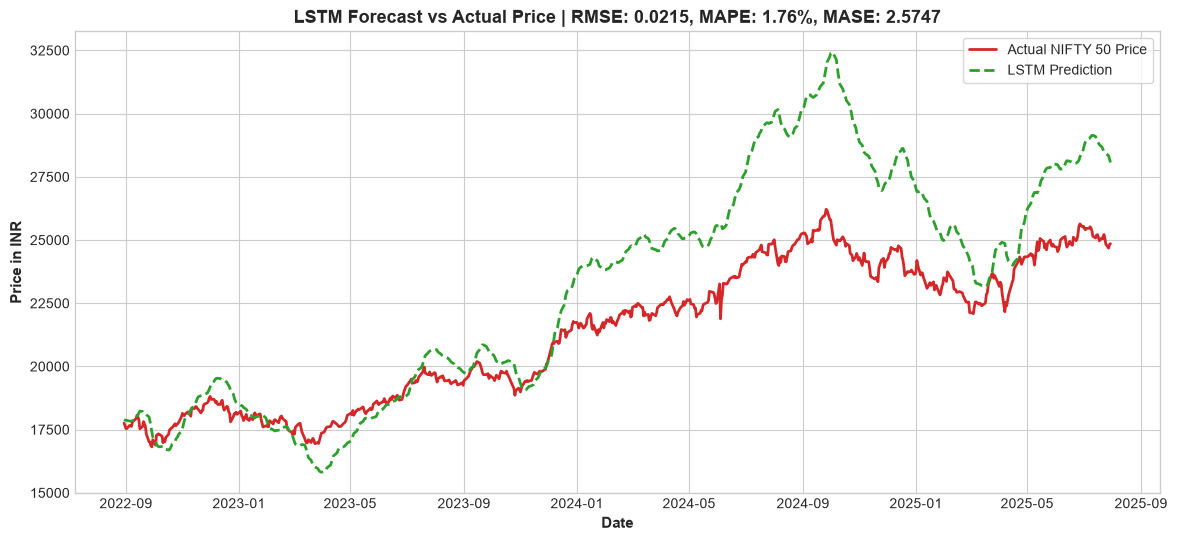

In [10]:
model_lstm = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    LSTM(64),
    Dropout(0.3),
    Dense(25, activation='relu'),
    Dense(1)
], name='LSTM')

model_lstm.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])
model_lstm.summary()

callbacks_lstm = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=0)
]
model_lstm.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=64, callbacks=callbacks_lstm, verbose=1)

test_predict_lstm = model_lstm.predict(X_test)
m_lstm = calculate_metrics(y_test, test_predict_lstm, y_train, 'LSTM')
all_metrics.append(m_lstm)
print(f"LSTM Metrics: RMSE={m_lstm['RMSE']:.4f}, MAPE={m_lstm['MAPE (%)']:.2f}%, MASE={m_lstm['MASE']:.4f}, R2={m_lstm['R2']:.4f}")

predictions_dict['LSTM'] = plot_forecast(test_dates, df2, test_predict_lstm, scaler, 'LSTM', m_lstm)


### 6. Model 2: Bidirectional LSTM (Bi-LSTM) Architecture

Model: "Bi-LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 128)            │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,953 (148.25 KB)

 Trainable params: 37,953 (148.25 KB)

 Non-trainable params: 0 (0.00 B)

...

 9/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step  

18/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step


Bi-LSTM Metrics: RMSE=0.0215, MAPE=1.71%, MASE=2.5414, R2=0.9672


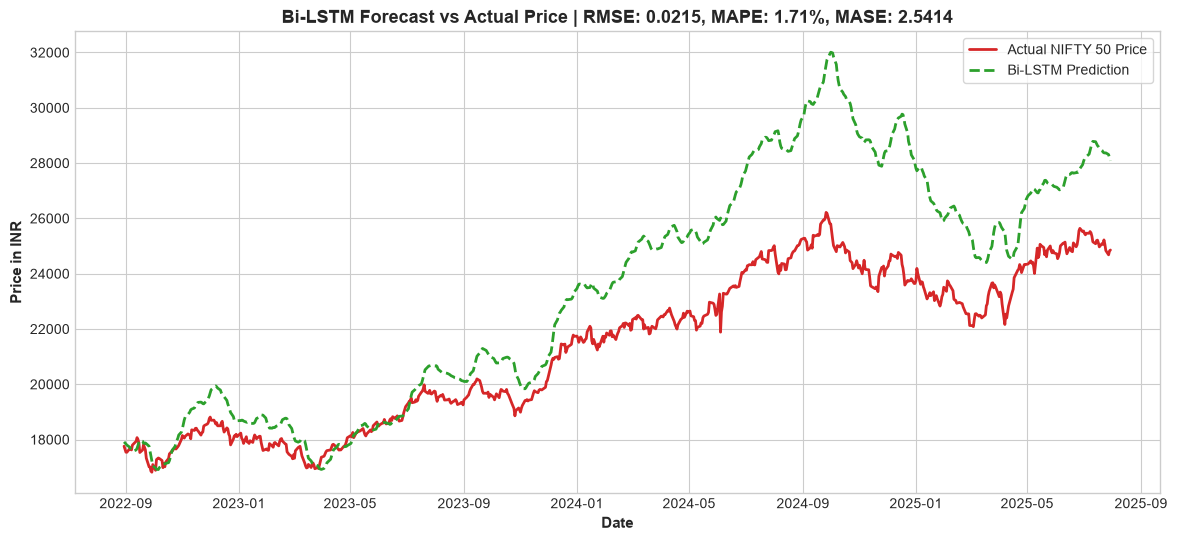

In [11]:
model_bilstm = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.3),
    Dense(32, activation='tanh'),
    Dropout(0.3),
    Dense(1)
], name='Bi-LSTM')

model_bilstm.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])
model_bilstm.summary()

callbacks_bilstm = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=0)
]
model_bilstm.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=64, callbacks=callbacks_bilstm, verbose=1)

test_predict_bilstm = model_bilstm.predict(X_test)
m_bilstm = calculate_metrics(y_test, test_predict_bilstm, y_train, 'Bi-LSTM')
all_metrics.append(m_bilstm)
print(f"Bi-LSTM Metrics: RMSE={m_bilstm['RMSE']:.4f}, MAPE={m_bilstm['MAPE (%)']:.2f}%, MASE={m_bilstm['MASE']:.4f}, R2={m_bilstm['R2']:.4f}")

predictions_dict['Bi-LSTM'] = plot_forecast(test_dates, df2, test_predict_bilstm, scaler, 'Bi-LSTM', m_bilstm)


### 7. Model 3: Gated Recurrent Unit (GRU) Architecture

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

...

 1/23 ━━━━━━━━━━━━━━━━━━━━ 3s 141ms/step

13/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step  

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


GRU Metrics: RMSE=0.0228, MAPE=1.80%, MASE=2.7810, R2=0.9632


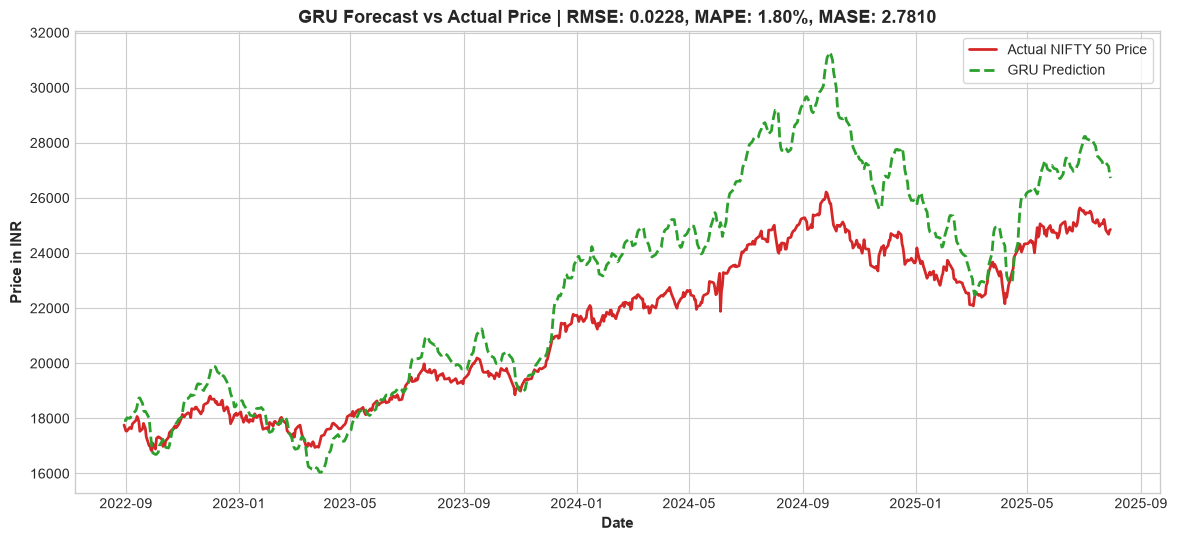

In [12]:
model_gru = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    GRU(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='tanh'),
    Dense(1)
], name='GRU')

model_gru.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])
model_gru.summary()

callbacks_gru = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=0)
]
model_gru.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=64, callbacks=callbacks_gru, verbose=1)

test_predict_gru = model_gru.predict(X_test)
m_gru = calculate_metrics(y_test, test_predict_gru, y_train, 'GRU')
all_metrics.append(m_gru)
print(f"GRU Metrics: RMSE={m_gru['RMSE']:.4f}, MAPE={m_gru['MAPE (%)']:.2f}%, MASE={m_gru['MASE']:.4f}, R2={m_gru['R2']:.4f}")

predictions_dict['GRU'] = plot_forecast(test_dates, df2, test_predict_gru, scaler, 'GRU', m_gru)


### 8. Model 4: Deep Multi-Layer GRU Architecture

Model: "Deep_GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                     │ (None, 60, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 60, 64)         │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,321 (188.75 KB)

 Trainable params: 48,321 (188.75 KB)

 Non-trainable params: 0 (0.00 B)

...

17/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

21/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


Deep GRU Metrics: RMSE=0.0220, MAPE=1.66%, MASE=2.5257, R2=0.9656


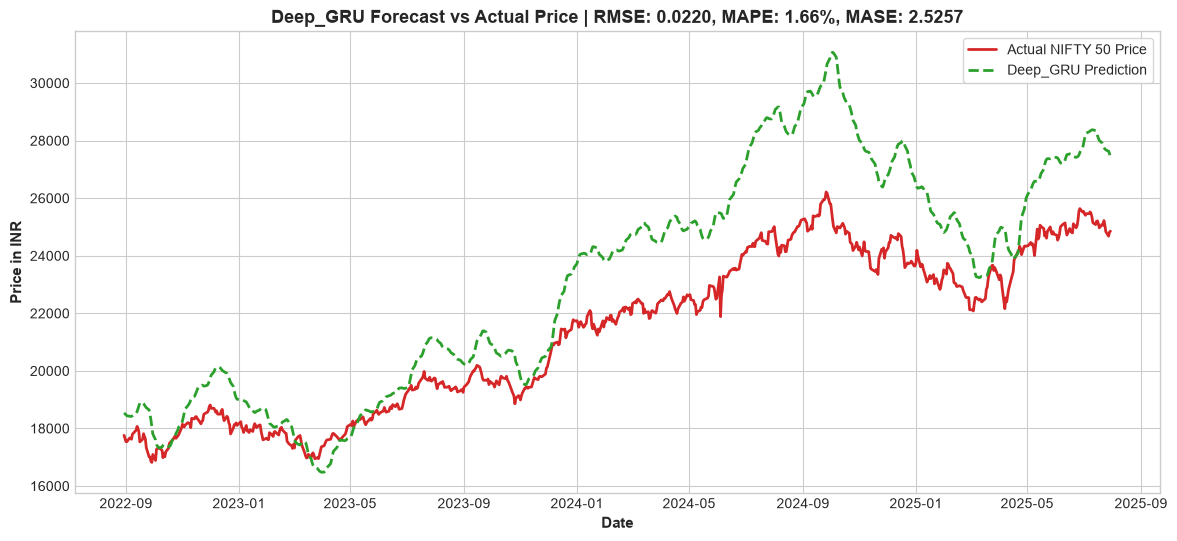

In [13]:
model_dgru = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    GRU(64, return_sequences=True),
    Dropout(0.3),
    GRU(64, return_sequences=True),
    Dropout(0.3),
    GRU(32, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='tanh'),
    Dense(1)
], name='Deep_GRU')

model_dgru.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])
model_dgru.summary()

callbacks_dgru = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=0)
]
model_dgru.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=64, callbacks=callbacks_dgru, verbose=1)

test_predict_dgru = model_dgru.predict(X_test)
m_dgru = calculate_metrics(y_test, test_predict_dgru, y_train, 'Deep_GRU')
all_metrics.append(m_dgru)
print(f"Deep GRU Metrics: RMSE={m_dgru['RMSE']:.4f}, MAPE={m_dgru['MAPE (%)']:.2f}%, MASE={m_dgru['MASE']:.4f}, R2={m_dgru['R2']:.4f}")

predictions_dict['Deep_GRU'] = plot_forecast(test_dates, df2, test_predict_dgru, scaler, 'Deep_GRU', m_dgru)


### 9. Comprehensive Model Benchmark & Comparative Visualizations

--- Benchmark Metrics Table ---
   Model     RMSE      MSE      MAE  MAPE (%)     MASE       R2
    LSTM 0.021484 0.000462 0.017907  1.758737 2.574703 0.967322
 Bi-LSTM 0.021539 0.000464 0.017676  1.707603 2.541394 0.967154
     GRU 0.022793 0.000520 0.019343  1.798463 2.781038 0.963219
Deep_GRU 0.022029 0.000485 0.017567  1.664571 2.525717 0.965644


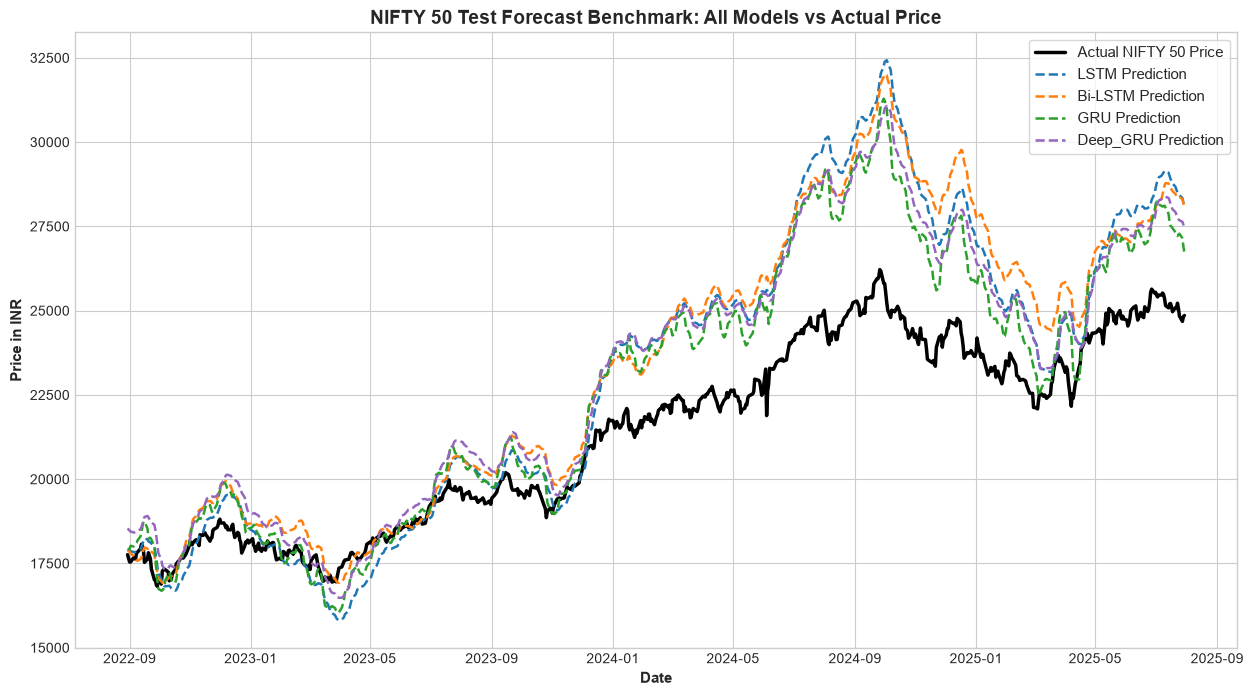

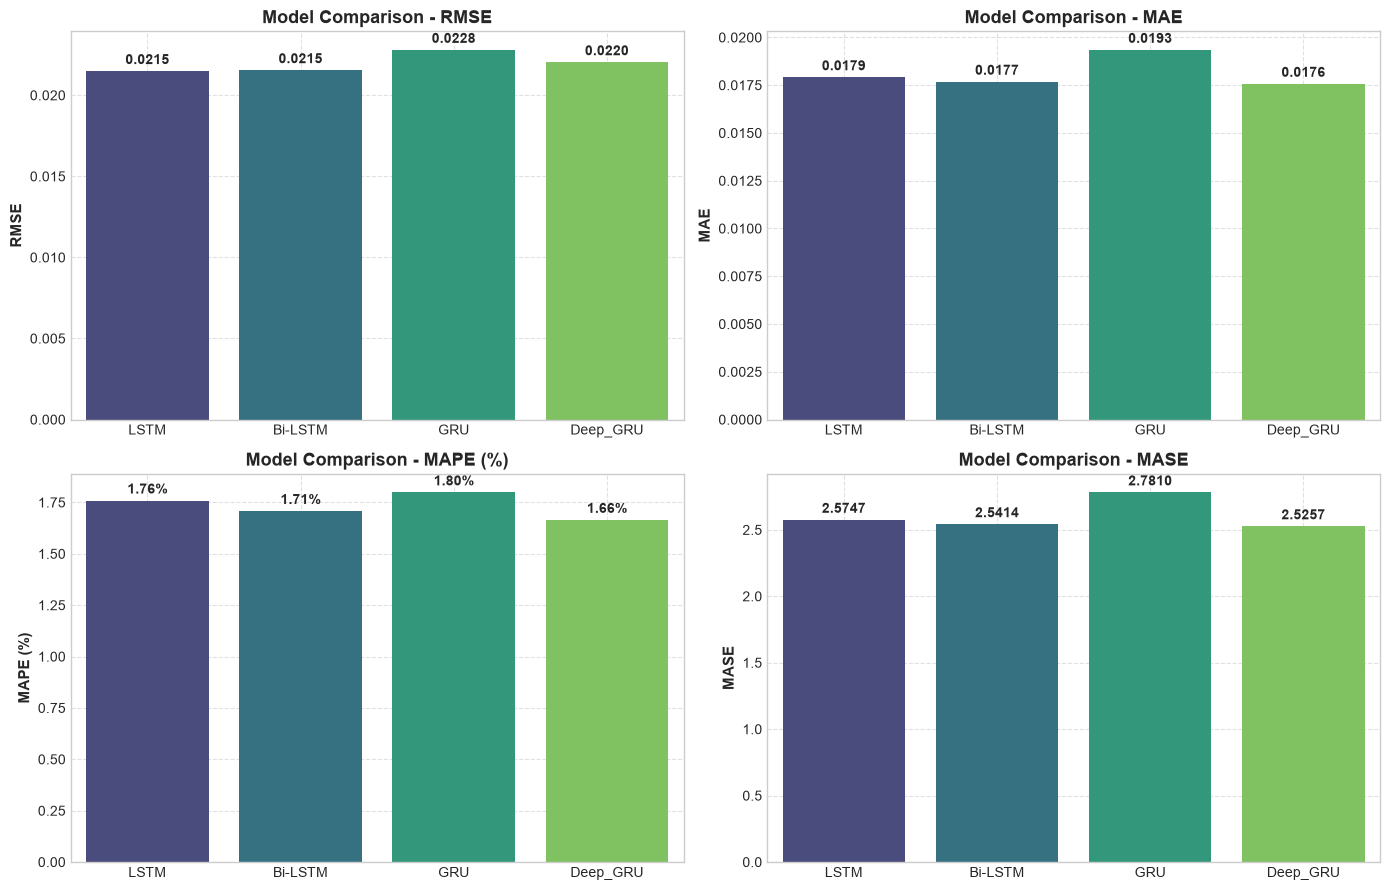

In [14]:
# Metrics Summary Table
metrics_df = pd.DataFrame(all_metrics)
print('--- Benchmark Metrics Table ---')
print(metrics_df.to_string(index=False))

# All Models Forecast Comparison Plot
plt.figure(figsize=(15, 8))
plt.plot(test_dates, predictions_dict['LSTM']['Actual_Price'], label='Actual NIFTY 50 Price', color='black', linewidth=2.5)

palette = {'LSTM': '#1f77b4', 'Bi-LSTM': '#ff7f0e', 'GRU': '#2ca02c', 'Deep_GRU': '#9467bd'}
for m_name, df_p in predictions_dict.items():
    plt.plot(test_dates, df_p['Predicted_Price'], label=f'{m_name} Prediction', linewidth=1.8, linestyle='--', color=palette[m_name])

plt.title('NIFTY 50 Test Forecast Benchmark: All Models vs Actual Price', fontsize=14, fontweight='bold')
plt.ylabel('Price in INR', fontsize=11, fontweight='bold')
plt.xlabel('Date', fontsize=11, fontweight='bold')
plt.legend(frameon=True, fontsize=11)
plt.show()

# Comparative Bar Chart
metrics_to_plot = ['RMSE', 'MAE', 'MAPE (%)', 'MASE']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, metric in enumerate(metrics_to_plot):
    sns.barplot(data=metrics_df, x='Model', y=metric, ax=axes[i], palette='viridis', hue='Model', legend=False)
    axes[i].set_title(f'Model Comparison - {metric}', fontsize=13, fontweight='bold')
    axes[i].set_ylabel(metric, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].grid(True, linestyle='--', alpha=0.6)
    
    for p in axes[i].patches:
        h = p.get_height()
        if not np.isnan(h):
            axes[i].annotate(f'{h:.4f}' if metric != 'MAPE (%)' else f'{h:.2f}%',
                            (p.get_x() + p.get_width() / 2., h),
                            ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3),
                            textcoords='offset points')

plt.tight_layout()
plt.show()


### 10. Fix 4 & 5 — Directional Accuracy & Financial Trading Metrics

**Fix 4 — The "Lag-1 Copy" Illusion:**
Price-level RMSE can look excellent even when the model is merely copying yesterday's price ($\hat{P}_{t+1} \approx P_t$).
The true test of a forecasting model is whether it correctly predicts the **direction** (Up / Down) of the next-day log-return:
$$r_{t+1} = \ln\left(\frac{P_{t+1}}{P_t}\right)$$
A random walk baseline achieves ~50% directional accuracy. A model must significantly exceed 50% to have real trading value.

**Fix 5 — Financial Trading Metrics:**
We simulate a simple **Long/Cash strategy**: go LONG when the model predicts a positive return, else stay in cash.
We then compute:
- **Hit Ratio (%)** — fraction of days the model correctly predicted Up vs Down
- **Annualised Sharpe Ratio** — risk-adjusted return (√252 scaling, risk-free = 0%)
- **Max Drawdown (%)** — worst peak-to-trough loss of the strategy
- **Strategy Return vs Buy-and-Hold** — total cumulative return comparison

In [15]:
def compute_trading_metrics(df_eval, model_name='Model'):
    actual = df_eval['Actual_Price'].values
    predicted = df_eval['Predicted_Price'].values

    # Log-returns
    actual_returns    = np.diff(np.log(actual))
    predicted_returns = np.diff(np.log(predicted))

    # Fix 4: Directional Accuracy
    hit_ratio = np.mean(np.sign(actual_returns) == np.sign(predicted_returns)) * 100

    # Fix 5: Long/Cash strategy
    signal            = (predicted_returns > 0).astype(float)
    strategy_returns  = signal * actual_returns
    bh_returns        = actual_returns

    strat_cum = np.cumprod(1 + strategy_returns)
    bh_cum    = np.cumprod(1 + bh_returns)

    strat_total = (strat_cum[-1] - 1) * 100
    bh_total    = (bh_cum[-1] - 1) * 100

    sharpe = (strategy_returns.mean() / strategy_returns.std()) * np.sqrt(252) if strategy_returns.std() > 0 else 0.0

    running_max  = np.maximum.accumulate(strat_cum)
    max_drawdown = ((strat_cum - running_max) / running_max).min() * 100

    return {
        'Model': model_name,
        'Hit Ratio (%)': round(hit_ratio, 2),
        'Sharpe Ratio': round(sharpe, 4),
        'Max Drawdown (%)': round(max_drawdown, 2),
        'Strategy Return (%)': round(strat_total, 2),
        'Buy & Hold (%)': round(bh_total, 2),
        '_strat_cum': strat_cum,
        '_bh_cum': bh_cum,
        '_dates': df_eval.index[1:]
    }

trading_results = {}
trading_summary = []
for mname, dfp in predictions_dict.items():
    t = compute_trading_metrics(dfp, model_name=mname)
    trading_results[mname] = t
    trading_summary.append({k: v for k, v in t.items() if not k.startswith('_')})

trading_df = pd.DataFrame(trading_summary)
print('=' * 75)
print('     DIRECTIONAL ACCURACY & FINANCIAL TRADING METRICS')
print('=' * 75)
print(trading_df.to_string(index=False))
print()
print('Strategy : LONG when predicted log-return > 0, else CASH')
print('Benchmark: Buy-and-Hold over the same test period')
print('Sharpe   : Annualised (252 trading days), risk-free = 0%')
print('Baseline : Random walk achieves ~50% directional accuracy')


     DIRECTIONAL ACCURACY & FINANCIAL TRADING METRICS
   Model  Hit Ratio (%)  Sharpe Ratio  Max Drawdown (%)  Strategy Return (%)  Buy & Hold (%)
    LSTM          53.06        0.4311            -10.53                10.16            36.8
 Bi-LSTM          52.78        0.6156             -8.40                15.23            36.8
     GRU          52.36        0.6766             -7.89                16.56            36.8
Deep_GRU          52.78        0.5680            -10.40                12.77            36.8

Strategy : LONG when predicted log-return > 0, else CASH
Benchmark: Buy-and-Hold over the same test period
Sharpe   : Annualised (252 trading days), risk-free = 0%
Baseline : Random walk achieves ~50% directional accuracy


### 11. Strategy Equity Curve — All Models vs Buy & Hold

Each curve shows $1 invested at the start of the test period, grown using the model's Long/Cash signal vs passively holding NIFTY 50.

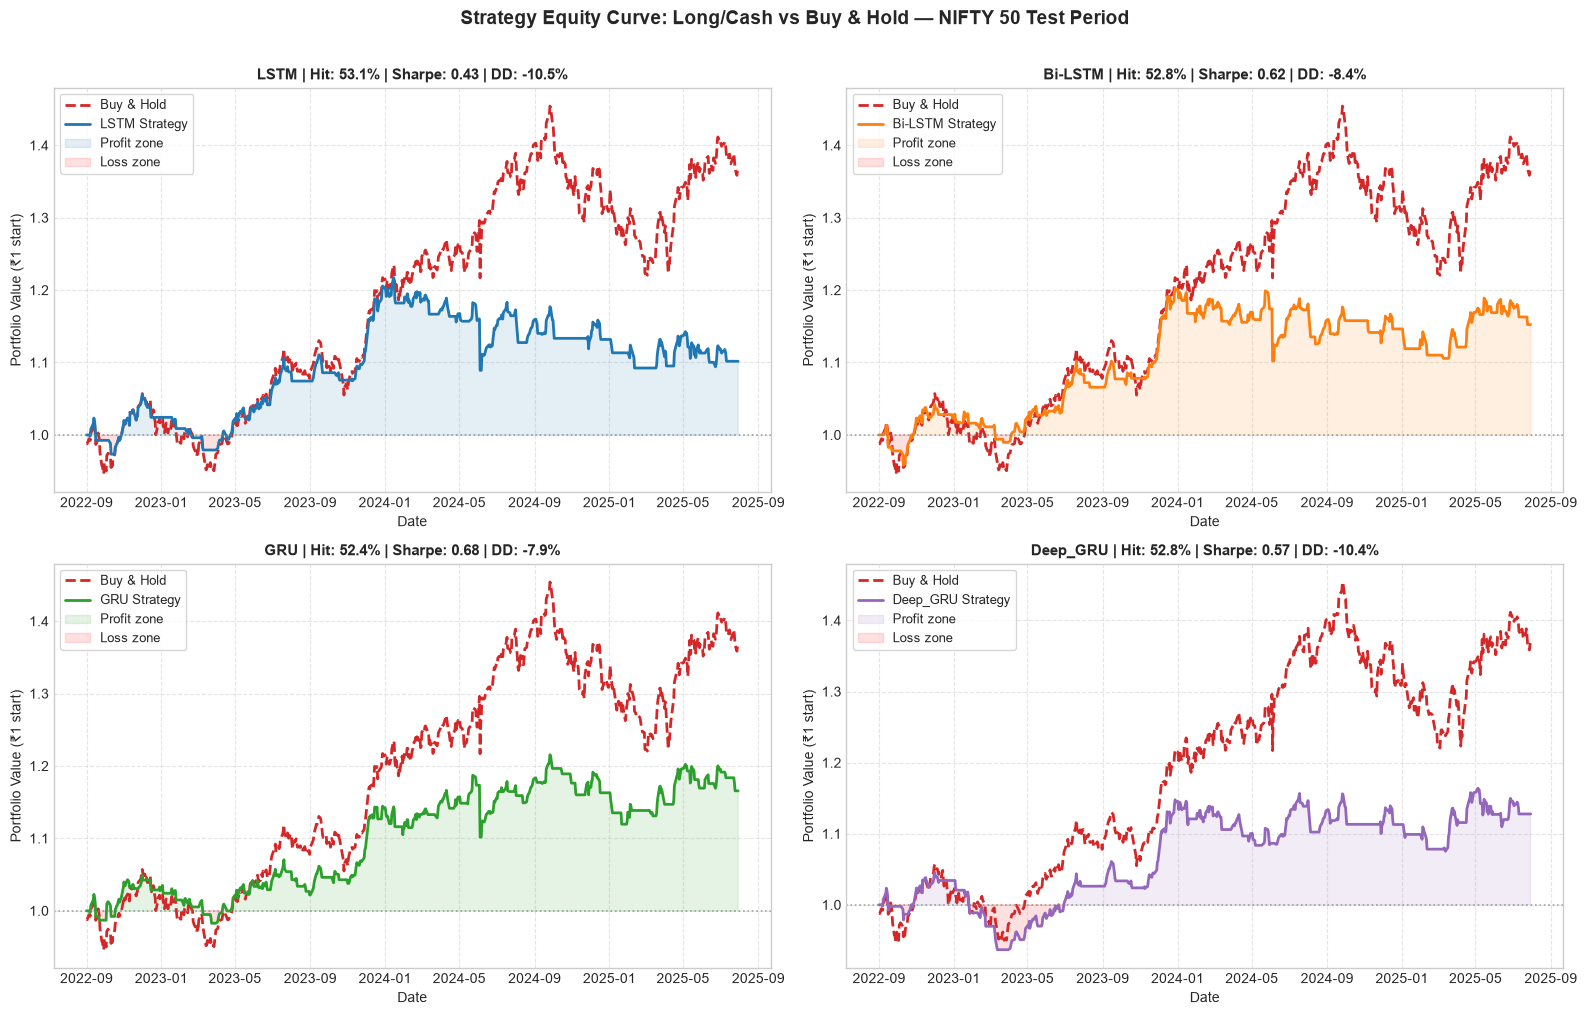

In [16]:
palette = {'LSTM': '#1f77b4', 'Bi-LSTM': '#ff7f0e', 'GRU': '#2ca02c', 'Deep_GRU': '#9467bd'}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, (mname, t) in enumerate(trading_results.items()):
    ax = axes[idx]
    dates = t['_dates']
    ax.plot(dates, t['_bh_cum'],    label='Buy & Hold',       color='#d62728', linewidth=2.0, linestyle='--')
    ax.plot(dates, t['_strat_cum'], label=f'{mname} Strategy', color=palette[mname], linewidth=2.0)
    ax.axhline(1.0, color='gray', linestyle=':', linewidth=1.2, alpha=0.7)
    ax.fill_between(dates, 1.0, t['_strat_cum'],
                    where=(t['_strat_cum'] >= 1.0), alpha=0.12, color=palette[mname], label='Profit zone')
    ax.fill_between(dates, 1.0, t['_strat_cum'],
                    where=(t['_strat_cum'] < 1.0),  alpha=0.12, color='red', label='Loss zone')
    ax.set_title(
        f"{mname} | Hit: {t['Hit Ratio (%)']:.1f}% | Sharpe: {t['Sharpe Ratio']:.2f} | DD: {t['Max Drawdown (%)']:.1f}%",
        fontsize=11, fontweight='bold'
    )
    ax.set_ylabel('Portfolio Value (₹1 start)', fontsize=10)
    ax.set_xlabel('Date', fontsize=10)
    ax.legend(fontsize=9, frameon=True)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Strategy Equity Curve: Long/Cash vs Buy & Hold — NIFTY 50 Test Period',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
